   # Fase esplorativa
   Obiettivo: vedere come si sono mossi i prezzi del carrello e le materie prime
   intorno alle crisi geopolitiche, prima di misurare qualsiasi effetto.

In [11]:
   import pandas as pd
   import matplotlib.pyplot as plt
   from pathlib import Path

   PROCESSED = Path("../data_market/processed")
   RAW = Path("../data_market/raw")

   PRODOTTI = ["pane", "pasta", "olio_girasole", "caffe", "zucchero", "latte", "carburanti"]

In [12]:
   dataset = pd.read_csv(PROCESSED / "dataset_mensile.csv", index_col="data", parse_dates=True)
   eventi = pd.read_csv(RAW / "eventi.csv", parse_dates=["data"])

   print(dataset.shape)
   eventi

(142, 33)


,data,evento,paesi_coinvolti,tipo,etichetta
0,2014-02-27,Occupazione russa della Crimea,Russia;Ucraina,guerra,Crimea
1,2020-03-11,Covid-19 dichiarato pandemia dall'OMS,Mondo,pandemia,Covid
2,2022-02-24,Invasione russa dell'Ucraina,Russia;Ucraina,guerra,Ucraina
3,2023-07-17,Fine dell'accordo sul grano del Mar Nero,Russia;Ucraina,commerciale,Fine accordo grano
4,2023-10-07,Attacco di Hamas e inizio della guerra a Gaza,Israele;Palestina,guerra,Gaza
5,2023-11-19,Inizio degli attacchi Houthi alle navi nel Mar...,Yemen;Israele;Stati Uniti,guerra,Mar Rosso
6,2025-04-02,Dazi USA del Liberation Day,Stati Uniti;Mondo,commerciale,Dazi USA
7,2025-06-13,Guerra dei 12 giorni tra Israele e Iran (con i...,Israele;Iran;Stati Uniti,guerra,Guerra 12 giorni
8,2026-02-28,Attacco di USA e Israele all'Iran e blocco del...,Stati Uniti;Israele;Iran,guerra,Iran


In [13]:
COLORI = {"guerra": "red", "commerciale": "orange", "pandemia": "purple"}

def disegna_eventi(ax, eventi, inizio, testo=True):
    """Aggiunge al grafico le linee degli eventi successivi a 'inizio'."""
    ev = eventi[eventi["data"] >= inizio].sort_values("data")
    tipi_visti = set()
    data_prec = None                                   # data dell'evento precedente

    for i, (_, e) in enumerate(ev.iterrows()):
        colore = COLORI.get(e["tipo"], "gray")
        etichetta = None if e["tipo"] in tipi_visti else e["tipo"].capitalize()
        tipi_visti.add(e["tipo"])
        ax.axvline(e["data"], color=colore, linestyle="--", linewidth=0.8, alpha=0.6,
                   label=etichetta)

        if testo:
            # evento a meno di 6 mesi dal precedente -> scritta a destra della linea
            vicino = data_prec is not None and (e["data"] - data_prec).days < 180
            lato = "left" if vicino else "right"
            # alterna alto (0.98) e basso (0.02), in coordinate del riquadro
            y, allinea = (0.98, "top") if i % 2 == 0 else (0.02, "bottom")
            ax.text(e["data"], y, f" {e['etichetta']} ", rotation=90,
                    va=allinea, ha=lato, fontsize=8, color=colore,
                    transform=ax.get_xaxis_transform(),
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

        data_prec = e["data"]

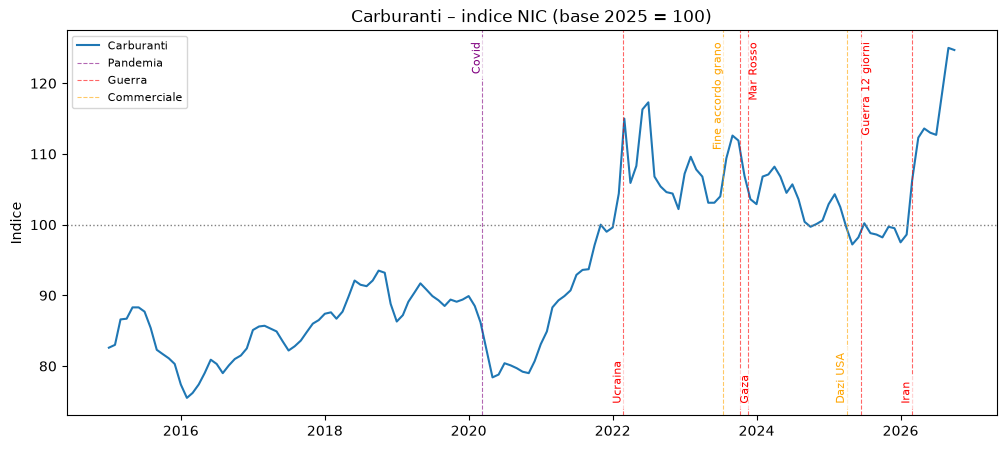

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(dataset.index, dataset["carburanti"], label="Carburanti")
ax.axhline(100, color="gray", linestyle=":", linewidth=1)
ax.set_title("Carburanti – indice NIC (base 2025 = 100)")
ax.set_ylabel("Indice")
ax.legend(loc="upper left")

disegna_eventi(ax, eventi, dataset.index.min())
ax.legend(loc="upper left", fontsize=8)
plt.show()

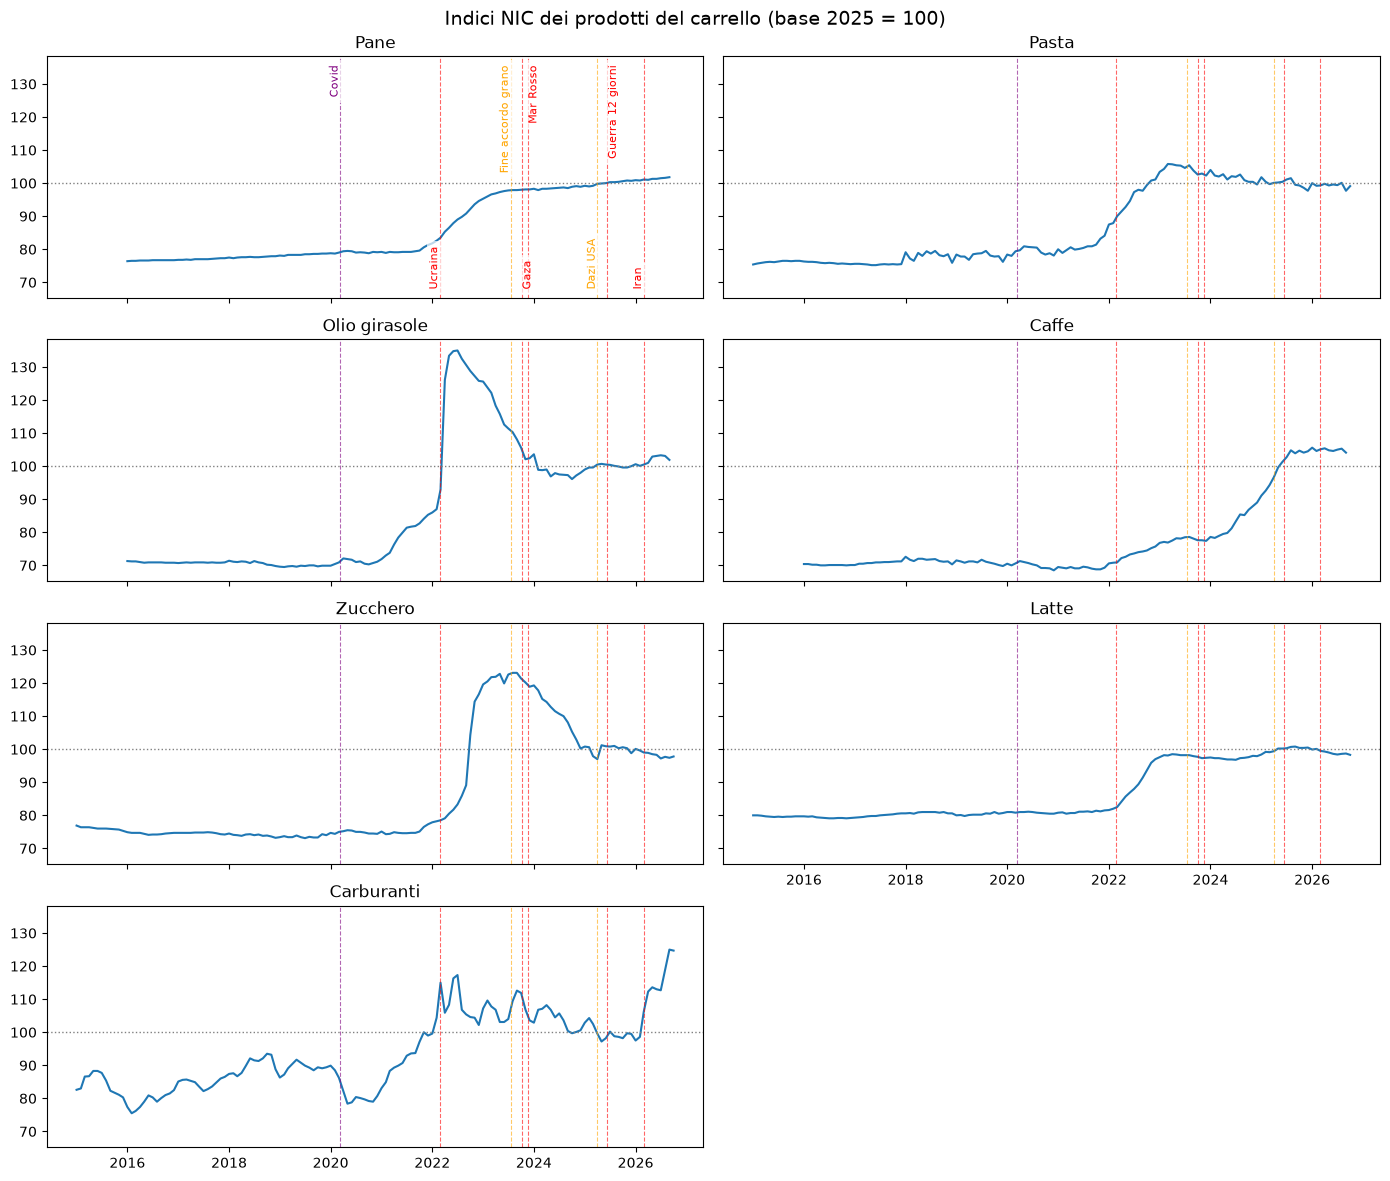

In [15]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True, sharey=True) #fig-->tutta la tela;axes-->i singoli grafici
axes = axes.flatten() #da una tabella di grafici, a grafici tutti allineati

for i, prodotto in enumerate(PRODOTTI):
    ax = axes[i]
    ax.plot(dataset.index, dataset[prodotto], color="tab:blue")
    ax.axhline(100, color="gray", linestyle=":", linewidth=1)
    ax.set_title(prodotto.replace("_", " ").capitalize())
    disegna_eventi(ax, eventi, dataset.index.min(), testo=(i == 0))  # scritte solo nel primo

axes[-1].axis("off")      # 7 prodotti in 8 caselle: spegne l'ultima vuota
fig.suptitle("Indici NIC dei prodotti del carrello (base 2025 = 100)", fontsize=14)
axes[5].tick_params(labelbottom=True)
fig.tight_layout()
plt.show()

## Grafico 2 – Variazioni su 12 mesi

Per ogni prodotto calcoliamo la **variazione percentuale tendenziale**: di quanto è cambiato
il prezzo rispetto allo **stesso mese dell'anno precedente**. È l'"inflazione" del singolo
prodotto.

$$\text{var\%}_t = \left(\frac{I_t}{I_{t-12}} - 1\right) \times 100$$

**Perché usare le variazioni invece degli indici:**
- **non dipendono dalla base**: con gli indici tutti i prodotti valgono circa 100 nel 2025
  per costruzione, con le variazioni questo effetto sparisce
- **eliminano la stagionalità**: si confronta sempre lo stesso mese (marzo con marzo),
  quindi gli effetti di raccolti ed estate si annullano

**Note sul calcolo:**
- il primo anno di ogni serie è vuoto, perché manca l'anno precedente con cui confrontarlo
  (per pane, olio di girasole e caffè le variazioni partono dal 2017)
- `fill_method=None` evita che pandas riempia i valori mancanti con quelli precedenti

**Come leggere il grafico:**
- area **rossa** = prezzi in aumento rispetto all'anno prima
- area **blu** = prezzi in calo
- linea verde al **2%** = obiettivo di inflazione della BCE, riferimento di un aumento "normale"

In [16]:
var12 = dataset[PRODOTTI].pct_change(12, fill_method=None) * 100
var12.loc["2022-06":"2022-09"].round(1)

,pane,pasta,olio_girasole,caffe,zucchero,latte,carburanti
data,,,,,,,
2022-06-01,11.0,18.1,68.7,6.1,9.5,7.2,28.2
2022-07-01,12.4,21.0,65.8,5.7,11.7,8.5,26.3
2022-08-01,13.4,21.1,62.2,6.6,15.0,10.1,14.1
2022-09-01,14.4,20.8,59.5,7.5,19.3,12.8,12.5


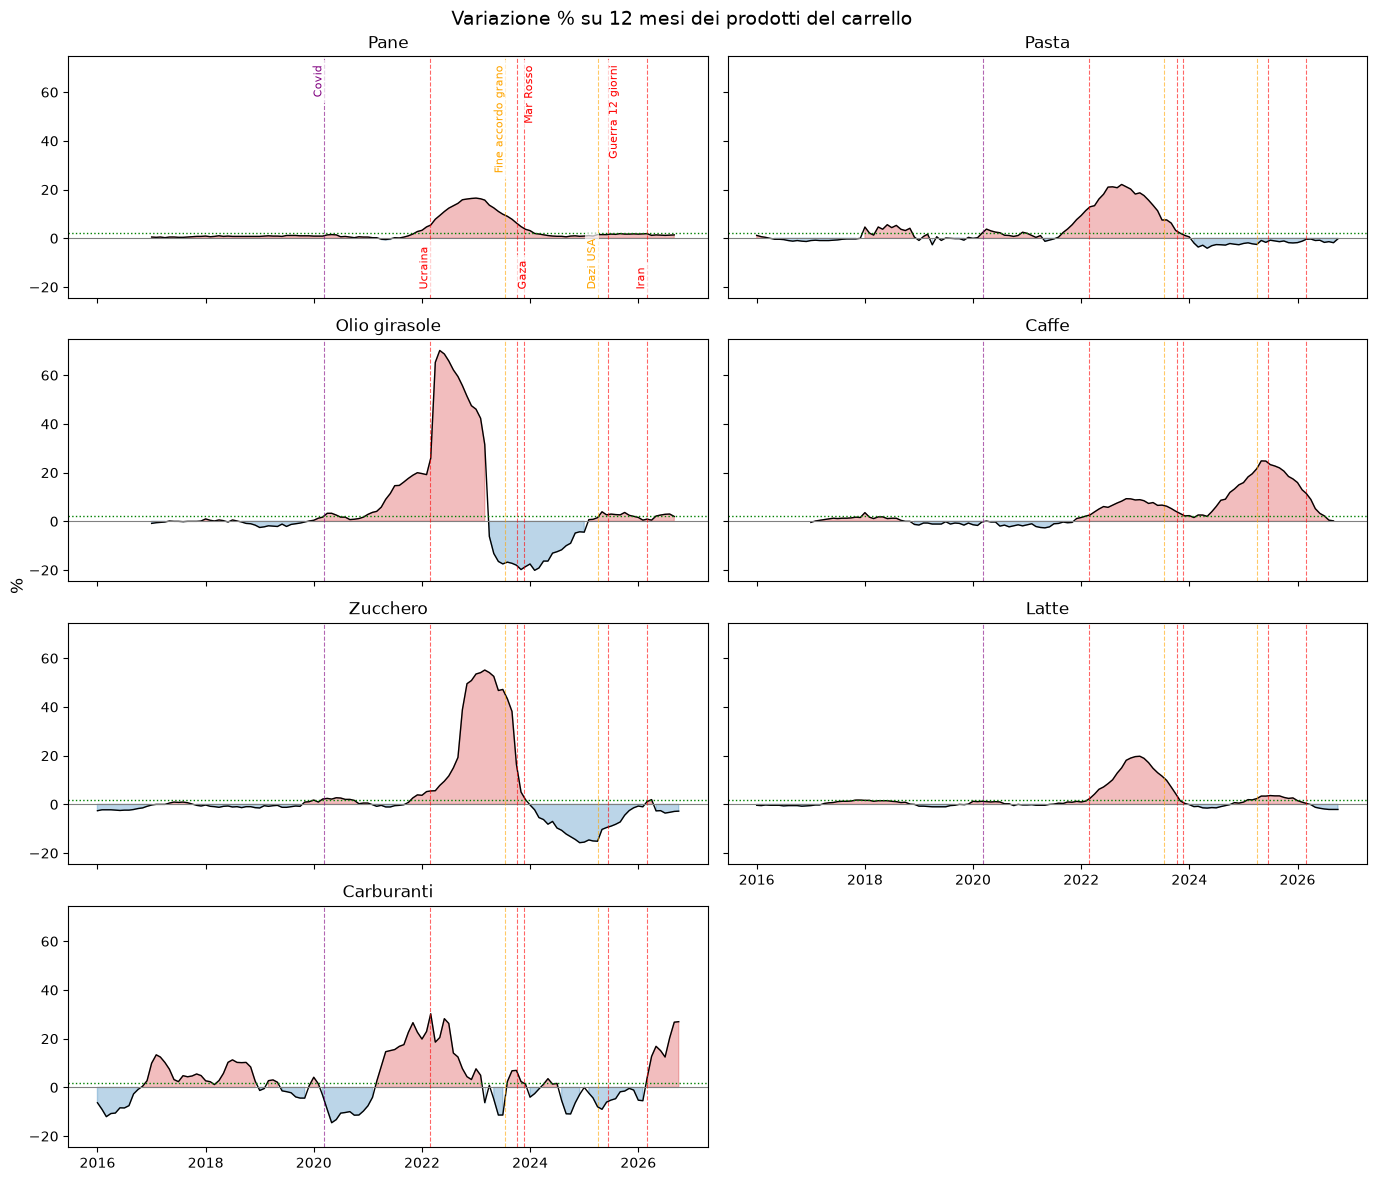

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True, sharey=True)
axes = axes.flatten()

for i, prodotto in enumerate(PRODOTTI):
    ax = axes[i]
    serie = var12[prodotto]
    ax.plot(serie.index, serie, color="black", linewidth=1)
    ax.fill_between(serie.index, serie, 0, where=serie > 0, color="tab:red", alpha=0.3)
    ax.fill_between(serie.index, serie, 0, where=serie < 0, color="tab:blue", alpha=0.3)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axhline(2, color="green", linestyle=":", linewidth=1)   # obiettivo BCE: 2%
    ax.set_title(prodotto.replace("_", " ").capitalize())
    disegna_eventi(ax, eventi, var12.index.min(), testo=(i == 0))

axes[-1].axis("off")
axes[5].tick_params(labelbottom=True)
fig.suptitle("Variazione % su 12 mesi dei prodotti del carrello", fontsize=14)
fig.supylabel("%")
fig.tight_layout()
plt.show()

### Osservazioni sul Grafico 2

**Intensità degli shock.** A parità di scala, i rincari più forti dopo l'invasione
dell'Ucraina riguardano i prodotti più vicini alle materie prime:
olio di girasole (picco circa +70% su 12 mesi), zucchero (circa +55%), carburanti
(circa +30%). Pasta, latte e pane restano tra +16% e +21%.

**Tempi di reazione diversi.** L'olio di girasole reagisce subito all'invasione
(febbraio 2022): l'Ucraina è il primo esportatore mondiale di girasole.
Lo zucchero raggiunge il picco solo nel 2023, quasi un anno dopo: lo shock si trasmette
con ritardo. La pasta inizia a salire già a fine 2021, **prima** della guerra:
una parte del rincaro ha altre cause (ripresa post-Covid, raccolti).

**"Razzo e piuma".** Dopo il picco, olio di girasole e zucchero scendono davvero
(fino a circa −20% e −15%), seguendo le materie prime. Pane e latte invece smettono
di salire ma non tornano indietro, e la pasta scende appena: nei prodotti lavorati
pesano anche salari, energia e imballaggi, che non sono diminuiti.

**Carburanti.** Sono il prodotto più legato agli eventi: picco nel 2022 con l'Ucraina
(attenuato dal taglio delle accise da marzo 2022) e di nuovo nel 2026 con la guerra
in Iran (circa +27%). Nel 2025 sono in calo.

**Caffè.** Il rincaro più forte (circa +25%) arriva nel 2025 e non coincide con
nessuna crisi dell'elenco. Nello stesso periodo l'energia scendeva, quindi
non è la spiegazione.

**2026.** Con la guerra in Iran salgono soprattutto i carburanti; l'olio di girasole
cresce poco, il latte scende. La crisi colpisce l'energia più dei prodotti alimentari,
almeno finora.

### Ipotesi da verificare nel Grafico 3
- Il rincaro del caffè nel 2025 dipende dal prezzo mondiale della materia prima
  (arabica e robusta), per cause climatiche nei paesi produttori.
- I prodotti che "seguono" la materia prima in salita e in discesa
  (girasole, zucchero) mostrano una relazione più stretta con i prezzi mondiali
  rispetto a pane, pasta e latte.

## Grafico 3 – Prezzi italiani e materie prime mondiali

Ogni pannello confronta un prodotto del carrello (indice ISTAT, linea nera spessa)
con la materia prima da cui dipende (prezzo mondiale, linee sottili colorate).

| Prodotto italiano | Materia prima di confronto | Fonte |
|---|---|---|
| Pane | Grano (US HRW) | World Bank Pink Sheet |
| Pasta | Grano (US HRW) | World Bank Pink Sheet |
| Olio di girasole | Olio di girasole | World Bank Pink Sheet |
| Caffè | Caffè Arabica e Robusta | World Bank Pink Sheet |
| Zucchero | Zucchero (mercato mondiale) | World Bank Pink Sheet |
| Latte | Indice FAO dei latticini | FAO |
| Carburanti | Petrolio Brent | World Bank Pink Sheet |

### Come sono resi confrontabili
I prezzi mondiali sono in dollari e con unità diverse ($/tonnellata, $/kg, $/barile),
mentre gli indici ISTAT sono in euro. Per confrontarli, ogni materia prima viene:
1. **convertita in euro**: prezzo in euro = prezzo in dollari ÷ cambio euro/dollaro (BCE).
   È il prezzo effettivamente pagato dalle aziende italiane: se l'euro si indebolisce,
   la materia prima costa di più anche a parità di prezzo in dollari.
2. **portata in base 2025 = 100**, come gli indici ISTAT.

Il grano duro, usato per la pasta, non è disponibile: si usa il grano tenero US HRW
come approssimazione.

### Come leggere il grafico
- I pannelli **non** hanno la stessa scala verticale: le materie prime oscillano molto
  più dei prezzi al consumo. Si confrontano le linee **dentro** ogni pannello.
- Le linee verticali tratteggiate sono gli eventi (stessi colori dei grafici precedenti).

### Domande guida
1. Il prezzo italiano **segue** la materia prima? Con quanto **ritardo**?
2. Quando la materia prima **scende**, il prezzo italiano scende anche lui?
   (verifica dell'effetto "razzo e piuma")
3. Il rincaro del **caffè nel 2025** è preceduto da un aumento di Arabica e Robusta?

In [18]:
def in_euro_base2025(serie):
    """Converte una serie in dollari in euro e la porta in base 2025 = 100."""
    in_euro = serie / dataset["eur_usd"]
    return in_euro / in_euro.loc["2025"].mean() * 100

# Ogni prodotto italiano con le materie prime da confrontare
CONFRONTI = {
    "pane": ["grano"],
    "pasta": ["grano"],
    "olio_girasole": ["girasole_mondo"],
    "caffe": ["caffe_arabica", "caffe_robusta"],
    "zucchero": ["zucchero_mondo"],
    "latte": ["fao_latticini"],
    "carburanti": ["brent"],
}

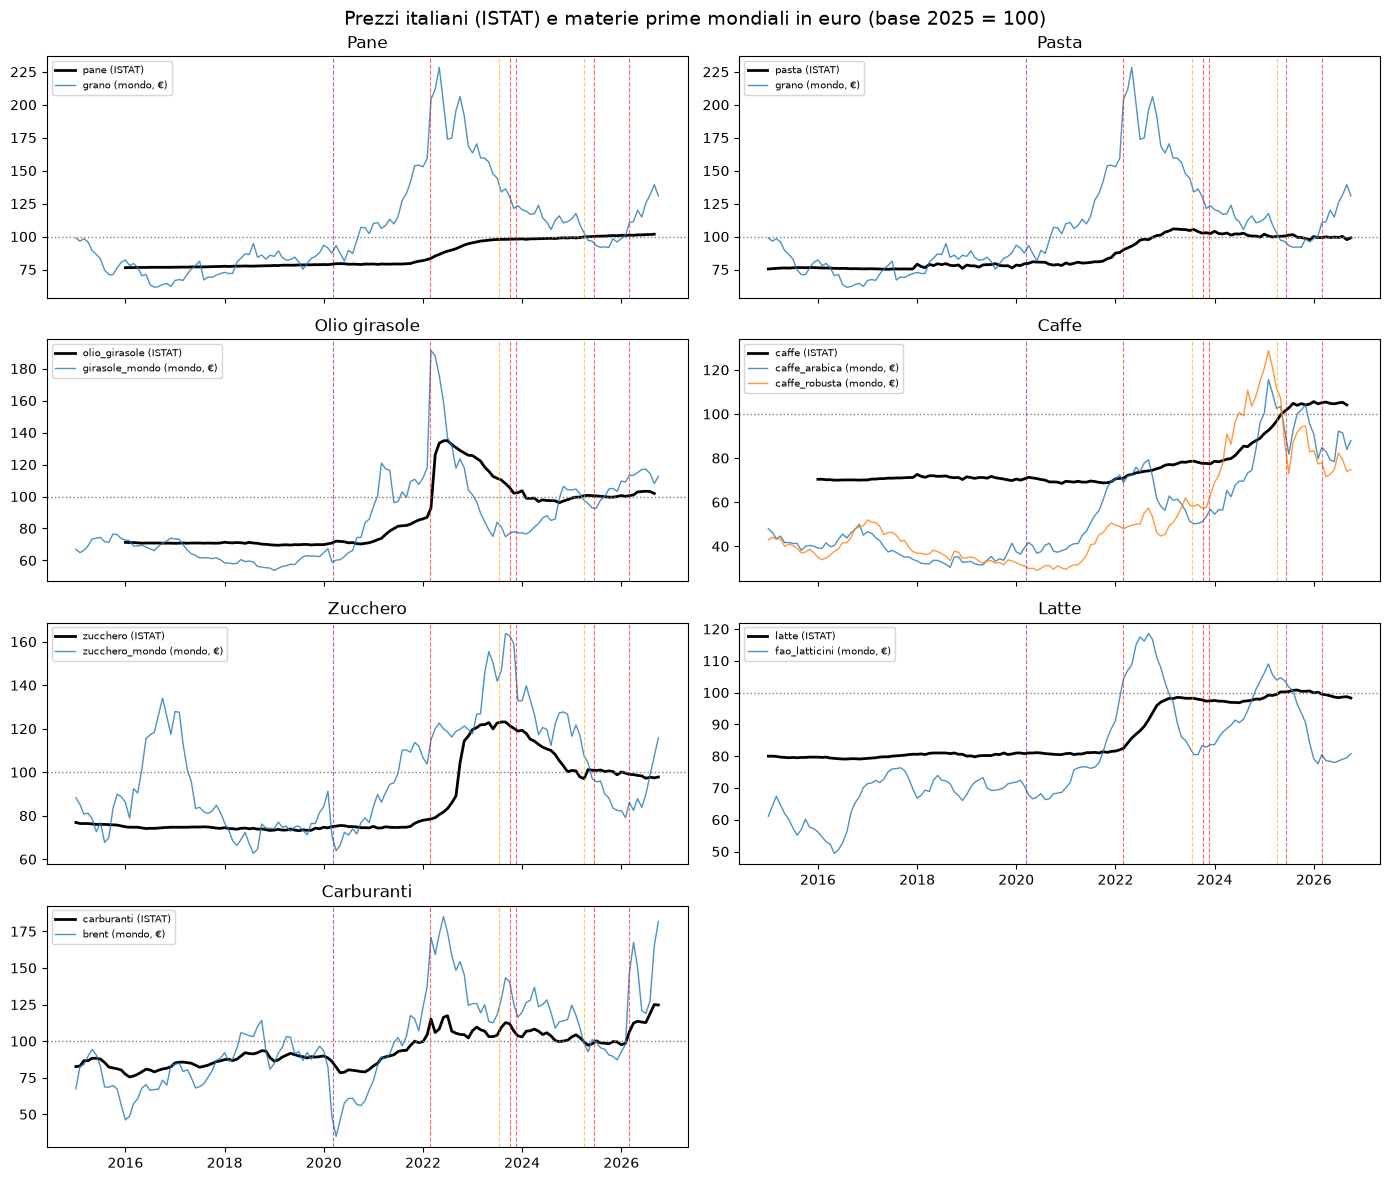

In [19]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
axes = axes.flatten()

for i, (prodotto, materie) in enumerate(CONFRONTI.items()):
    ax = axes[i]
    ax.plot(dataset.index, dataset[prodotto], color="black", linewidth=2,
            label=f"{prodotto} (ISTAT)")
    for materia in materie:
        ax.plot(dataset.index, in_euro_base2025(dataset[materia]),
                linewidth=1, alpha=0.8, label=f"{materia} (mondo, €)")
    ax.axhline(100, color="gray", linestyle=":", linewidth=1)
    ax.set_title(prodotto.replace("_", " ").capitalize())
    disegna_eventi(ax, eventi, dataset.index.min(), testo=False)
    ax.legend(handles=ax.lines[:1 + len(materie)], fontsize=7, loc="upper left")

axes[-1].axis("off")
axes[5].tick_params(labelbottom=True)
fig.suptitle("Prezzi italiani (ISTAT) e materie prime mondiali in euro (base 2025 = 100)", fontsize=14)
fig.tight_layout()
plt.show()

### Osservazioni sul Grafico 3

**Il prezzo italiano segue la materia prima, ma attenuato.**
- **Carburanti**: seguono il Brent quasi senza ritardo, ma con oscillazioni molto più
  piccole. Nel 2020 il Brent crolla di circa il 60%, i carburanti di circa il 10%:
  le accise sono una cifra fissa al litro e attutiscono le variazioni percentuali.
- **Olio di girasole**: il prezzo mondiale salta subito dopo l'invasione dell'Ucraina,
  quello italiano lo segue con 1–2 mesi di ritardo.
- **Zucchero e latte**: reagiscono con un ritardo maggiore.

**"Razzo e piuma" confermato.** Quando le materie prime scendono, i prezzi italiani
scendono poco o niente:
- il grano dopo il picco del 2022 torna sui livelli del 2025, pane e pasta restano alti
- l'olio di girasole mondiale scende sotto 80, quello italiano si ferma intorno a 100
- l'indice mondiale dei latticini scende nel 2026, il latte italiano no

**Caffè 2025: ipotesi confermata.** Arabica e Robusta salgono prima del caffè italiano
(la Robusta ha un picco a inizio 2025); il caffè italiano sale dopo, nel corso del 2025,
e resta alto quando le materie prime riscendono nel 2026. Il rincaro non è legato
a una crisi geopolitica ma al prezzo mondiale della materia prima.

**Il grano saliva prima della guerra.** Il prezzo mondiale del grano cresce già
dal 2021: una parte del rincaro di pane e pasta non è dovuta all'invasione dell'Ucraina.

**Non tutti gli shock mondiali arrivano in Italia.** Nel 2016–2017 lo zucchero mondiale
sale molto, quello italiano resta fermo.

**Da seguire.** Nel 2026 grano e zucchero mondiali stanno risalendo,
i prezzi italiani non ancora.

## Grafico 4 – Rischio geopolitico

**Pannello 1:** indice GPR globale e le sue due componenti, minacce (tensioni, minacce
di guerra) e atti (guerre iniziate, attacchi). Base 1985–2019 = 100.

**Pannello 2:** indici per paese, cioè la quota di articoli che collegano quel paese
a guerre, minacce o attacchi (senza distinguere aggressore e bersaglio).

Le due scale sono diverse e non vanno confrontate tra loro.

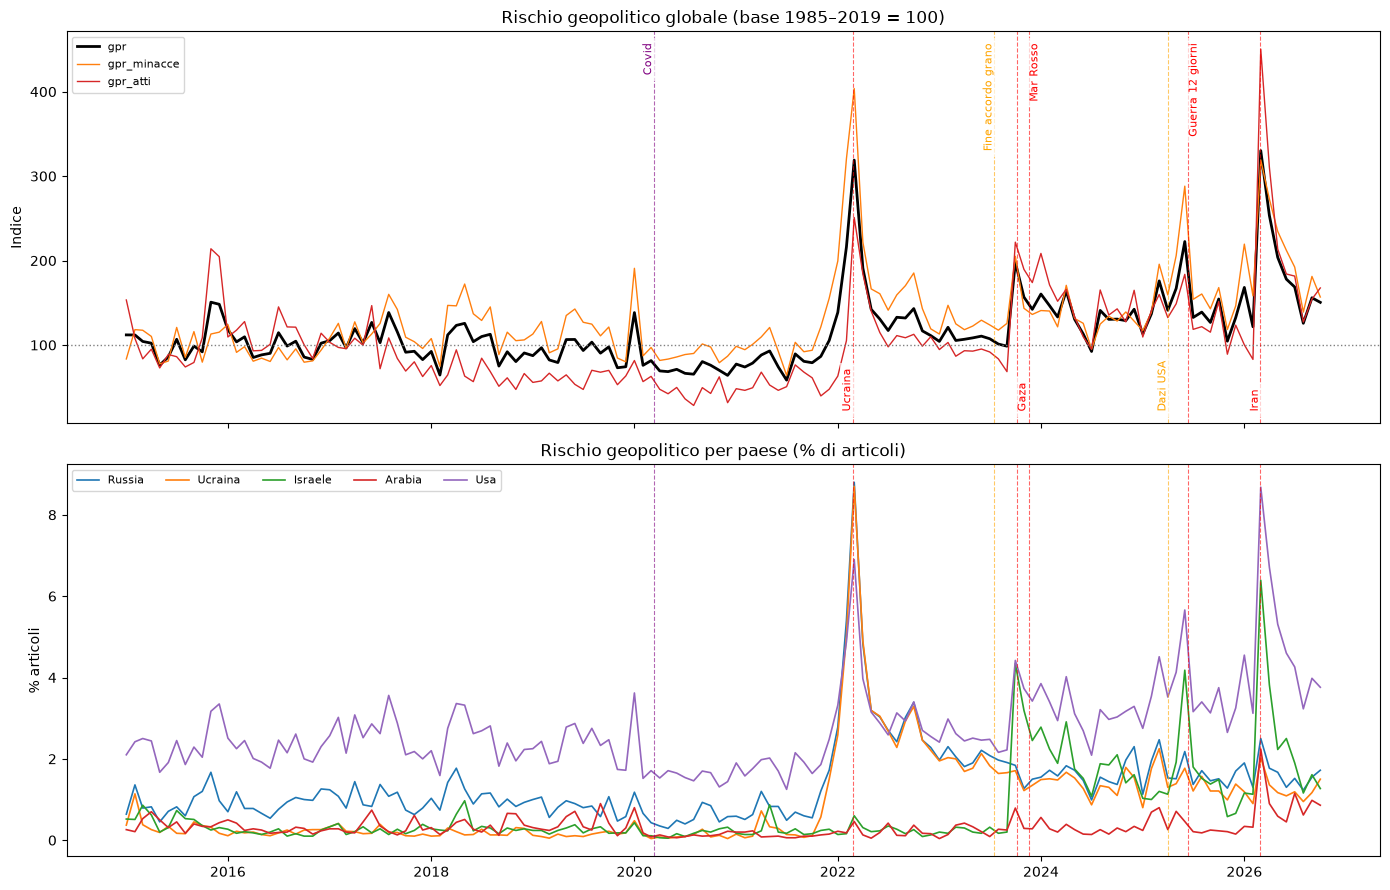

In [20]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# --- Pannello 1: indici globali ---
for col, colore in [("gpr", "black"), ("gpr_minacce", "tab:orange"), ("gpr_atti", "tab:red")]:
    ax1.plot(dataset.index, dataset[col], color=colore,
             linewidth=2 if col == "gpr" else 1, label=col)
ax1.axhline(100, color="gray", linestyle=":", linewidth=1)
ax1.set_title("Rischio geopolitico globale (base 1985–2019 = 100)")
ax1.set_ylabel("Indice")
disegna_eventi(ax1, eventi, dataset.index.min())
ax1.legend(handles=ax1.lines[:3], fontsize=8, loc="upper left")

# --- Pannello 2: indici per paese ---
PAESI = ["gpr_russia", "gpr_ucraina", "gpr_israele", "gpr_arabia", "gpr_usa"]
for col in PAESI:
    ax2.plot(dataset.index, dataset[col], linewidth=1.2,
             label=col.replace("gpr_", "").capitalize())
ax2.set_title("Rischio geopolitico per paese (% di articoli)")
ax2.set_ylabel("% articoli")
disegna_eventi(ax2, eventi, dataset.index.min(), testo=False)
ax2.legend(handles=ax2.lines[:len(PAESI)], fontsize=8, loc="upper left", ncol=5)

fig.tight_layout()
plt.show()

### Osservazioni sul Grafico 4

**Minacce e atti si comportano in modo diverso a seconda della crisi.**
- **Ucraina 2022**: le minacce salgono già nei mesi precedenti e toccano il massimo
  (circa 400) a febbraio, più degli atti. La guerra era attesa.
- **Iran 2026**: sono gli atti a raggiungere il valore più alto della serie (circa 450),
  sopra le minacce. L'attacco è stato improvviso, senza una lunga fase di tensione.
  Nel 2022 i mercati hanno avuto tempo per "anticipare" lo shock, nel 2026 molto meno.

**Quali eventi si vedono nel GPR.**
- Chiaramente visibili: invasione dell'Ucraina (2022), Gaza (2023, con il balzo
  dell'indice di Israele), guerra in Iran (2026).
- Quasi invisibili: fine dell'accordo sul grano (2023), dazi USA (2025).
- Il Mar Rosso non si distingue da Gaza.
- Il Covid non è un evento geopolitico e il GPR non lo misura.

**Picchi non presenti nell'elenco degli eventi** (da verificare):
- fine 2015: picco degli atti (probabili attentati di Parigi, novembre 2015)
- inizio 2020: picco delle minacce (probabili tensioni USA–Iran, non il Covid)

**Un rischio geopolitico alto non significa sempre prezzi alti.**
Fine 2015, inizio 2020 e Gaza 2023 hanno picchi del GPR senza rincari forti del carrello
(Grafico 2). Ucraina 2022 e Iran 2026 colpiscono invece materie prime e rotte
commerciali, e lì i prezzi salgono. Ipotesi da verificare nella Fase 4:
**conta dove colpisce una crisi, non quanto se ne parla.**

La guerra dei 12 giorni tra Israele e Iran (13–24 giugno 2025), individuata grazie al
picco del GPR, è stata aggiunta all'elenco degli eventi.

## Riepilogo della Fase esplorativa

### Le scoperte principali

**1. Le crisi colpiscono attraverso le materie prime, non in generale.**
I rincari più forti dopo l'invasione dell'Ucraina riguardano i prodotti più legati alle
materie prime colpite: olio di girasole (circa +70% su 12 mesi) e zucchero (circa +55%).
Con la guerra in Iran del 2026 sale soprattutto l'energia (carburanti circa +27%),
mentre i prodotti alimentari si muovono poco.

**2. Un rischio geopolitico alto non basta a far salire i prezzi.**
Il GPR ha picchi anche in momenti senza rincari (fine 2015, inizio 2020, Gaza 2023).
I prezzi salgono quando una crisi tocca materie prime o rotte commerciali, come nel 2022
(grano e girasole dal Mar Nero) e nel 2026 (petrolio e gas da Hormuz).
Conta dove colpisce una crisi, non quanto se ne parla.

**3. I prezzi salgono veloci e scendono lenti ("razzo e piuma").**
Quando le materie prime riscendono, olio di girasole e zucchero seguono in parte;
pane, pasta e latte restano invece sui livelli raggiunti. Nei prodotti lavorati
pesano anche costi (salari, energia, imballaggi) che non sono tornati indietro.

**4. Non tutto è geopolitica: servono i confondenti.**
- Grano e pasta salivano già nel 2021, prima della guerra (ripresa post-Covid, raccolti).
- Il rincaro più forte del caffè (2025) segue il prezzo mondiale della materia prima,
  non una crisi.
- Il taglio delle accise del 2022 ha attenuato l'aumento dei carburanti.

**5. I tempi di reazione sono diversi.**
L'olio di girasole reagisce in 1–2 mesi, lo zucchero quasi un anno dopo.
Le crisi annunciate (Ucraina 2022) fanno salire il rischio già nei mesi precedenti;
quelle improvvise (Iran 2026) no.

### Ipotesi da verificare nella Fase 4
- La correlazione tra prezzi italiani e materie prime è più forte di quella con il GPR.
- I prezzi italiani seguono le materie prime con un ritardo diverso per ogni prodotto.
- Gli aumenti delle materie prime si trasmettono ai prezzi italiani più delle diminuzioni.